In [32]:
# %matplotlib notebook
%matplotlib widget

from skmultiflow.data import RandomRBFGenerator
from skmultiflow.bayes import NaiveBayes
from skmultiflow.prototype import RobustSoftLearningVectorQuantization
from skmultiflow.evaluation import EvaluatePrequential
from skmultiflow.neural_networks import PerceptronMask
from skmultiflow.trees import HoeffdingTreeClassifier
from skmultiflow.lazy import KNNClassifier

import pandas as pd
import numpy as np
import importlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs

import clp.sk_clp
from clp.sk_clp import CLP

In [327]:
n_classes=100
X, y, centers = make_blobs(n_samples=3000, n_features=256, centers=n_classes, cluster_std=10*np.random.rand(n_classes,1), 
                           center_box=(-10.0, 10.0), shuffle=False, random_state=None, return_centers=True)

y=y[:,None]

In [328]:
# 2. Get data from the stream
print(X.shape, y.shape, centers.shape)

(3000, 256) (3000, 1) (100, 256)


In [329]:
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics.pairwise import cosine_similarity

# euclidian distance similarity for population coded data
distances = pdist(X, metric='euclidean')
dist_matrix = squareform(distances)
# dist_matrix = min_max_scale(dist_matrix)
# euc_sim = 1/np.exp(dist_matrix)

cos_sim = cosine_similarity(X)



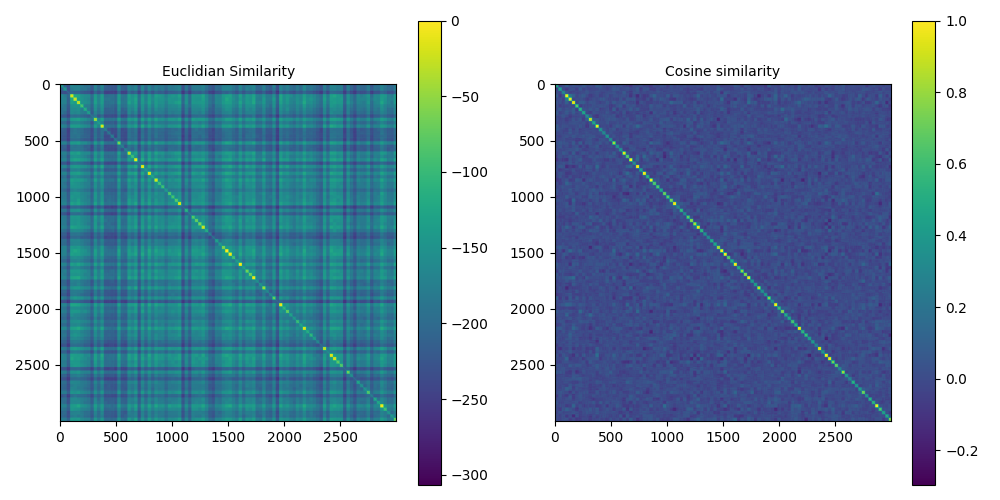

In [330]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))
im1 = ax1.imshow(-dist_matrix)
im2 = ax2.imshow(cos_sim)
# im3 = ax3.imshow(u_data_th1_sc)
ax1.set_title("Euclidian Similarity", fontsize=10)
ax2.set_title("Cosine similarity", fontsize=10)
fig.colorbar(im1, ax=ax1)
fig.colorbar(im2, ax=ax2)
plt.tight_layout()
plt.show()

In [338]:
importlib.reload(clp.sk_clp)
from clp.sk_clp import CLP
clp_classifier = CLP(sim_metric='euclidean',
                    n_protos=300,
                    num_classes=n_classes,
                    alpha_init=1, 
                    sim_th_init=-250, 
                    max_allowed_mistakes=6,
                    tau_sim_th_pos=20, 
                    tau_sim_th_neg=126,
                    k_sim_th_pos=1.2,
                    k_sim_th_neg=0.8,
                    device='cpu', 
                    verbose=2)

In [339]:
importlib.reload(clp.sk_clp)
from clp.sk_clp import CLP
clp_classifier = CLP(sim_metric='dot_product',
                    n_protos=300,
                    num_classes=n_classes,
                    alpha_init=1, 
                    sim_th_init=0.44, 
                    max_allowed_mistakes=6,
                    tau_sim_th_pos=20, 
                    tau_sim_th_neg=126,
                    k_sim_th_pos=0.77,
                    k_sim_th_neg=1.1,
                    device='cpu', 
                    verbose=2)

In [340]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.90)
clp_classifier.fit(X_train,y_train)

-----------------------------------------------------------
sims:   tensor([0., 0., 0., 0., 0.])
simth:  tensor([[0.44, 0.44, 0.44, 0.44, 0.44]])
labels: tensor([[100., 100., 100., 100., 100.]])
alphas: tensor([[1., 1., 1., 1., 1.]])
Novel Label!
-----------------------------------------------------------
sims:   tensor([0.09, 0.00, 0.00, 0.00, 0.00])
simth:  tensor([[0.44, 0.44, 0.44, 0.44, 0.44]])
labels: tensor([[ 82., 100., 100., 100., 100.]])
alphas: tensor([[0.50, 1.00, 1.00, 1.00, 1.00]])
Novel Label!
-----------------------------------------------------------
sims:   tensor([0.05, 0.00, 0.00, 0.00, 0.00])
simth:  tensor([[0.44, 0.44, 0.44, 0.44, 0.44]])
labels: tensor([[ 82., 100., 100., 100., 100.]])
alphas: tensor([[0.50, 1.00, 1.00, 1.00, 1.00]])
Novel Label!
-----------------------------------------------------------
sims:   tensor([0.00, 0.00, 0.00, 0.00, 0.00])
simth:  tensor([[0.44, 0.44, 0.44, 0.44, 0.44]])
labels: tensor([[ 82., 100., 100., 100., 100.]])
alphas: tensor

In [341]:
from sklearn.metrics import accuracy_score
y_pred = clp_classifier.predict(X_test)
acc = accuracy_score(y_test,y_pred)
print(acc)
print(clp_classifier.next_alloc_id_)

-----------------------------------------------------------
sims:   tensor([92.62, 16.28, 14.21, 14.06, 13.66])
simth:  tensor([[0.46, 0.45, 0.46, 0.44, 0.44]])
labels: tensor([[24., 67., 21., 58., 12.]])
alphas: tensor([[0.33, 0.25, 0.17, 0.50, 0.50]])
-----------------------------------------------------------
sims:   tensor([94.58, 17.21, 15.37, 14.48, 14.43])
simth:  tensor([[0.45, 0.46, 0.44, 0.48, 0.44]])
labels: tensor([[85., 50., 16., 34., 64.]])
alphas: tensor([[0.33, 0.33, 0.50, 0.14, 0.50]])
-----------------------------------------------------------
sims:   tensor([85.32, 14.87, 12.54, 12.47, 12.20])
simth:  tensor([[0.45, 0.50, 0.44, 0.46, 0.44]])
labels: tensor([[99., 57., 87., 53.,  2.]])
alphas: tensor([[0.25, 0.17, 0.50, 0.33, 0.50]])
-----------------------------------------------------------
sims:   tensor([54.37, 27.47, 27.37, 25.82, 22.26])
simth:  tensor([[0.44, 0.44, 0.44, 0.44, 0.44]])
labels: tensor([[44., 23., 19., 77., 64.]])
alphas: tensor([[0.50, 0.50, 0.50

In [ ]:
clp_classifier.hits_

In [168]:
alloc_protos = clp_classifier.prototypes_[(clp_classifier.proto_labels_<n_classes).squeeze(),:]
emb_and_protos = np.concatenate((X, alloc_protos), 0)
emb_and_protos.shape

(3239, 1000)

In [169]:
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, learning_rate='auto', n_jobs=-1, n_iter_without_progress=100, verbose=2,
                 init='pca', perplexity=110, n_iter=2000, metric='cosine').fit_transform(emb_and_protos)

[t-SNE] Computing 331 nearest neighbors...
[t-SNE] Indexed 3239 samples in 0.003s...
[t-SNE] Computed neighbors for 3239 samples in 0.837s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3239
[t-SNE] Computed conditional probabilities for sample 2000 / 3239
[t-SNE] Computed conditional probabilities for sample 3000 / 3239
[t-SNE] Computed conditional probabilities for sample 3239 / 3239
[t-SNE] Mean sigma: 0.221890
[t-SNE] Computed conditional probabilities in 0.236s


/home/ehajizad/ss_learning/ssl_env/lib/python3.8/site-packages/sklearn/manifold/_t_sne.py:991: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  warnings.warn(


[t-SNE] Iteration 50: error = 72.9778748, gradient norm = 0.0480347 (50 iterations in 5.183s)
[t-SNE] Iteration 100: error = 62.3819771, gradient norm = 0.0427627 (50 iterations in 4.287s)
[t-SNE] Iteration 150: error = 57.7625771, gradient norm = 0.0219035 (50 iterations in 3.968s)
[t-SNE] Iteration 200: error = 55.7254105, gradient norm = 0.0117910 (50 iterations in 5.076s)
[t-SNE] Iteration 250: error = 55.3093681, gradient norm = 0.0093427 (50 iterations in 3.905s)
[t-SNE] KL divergence after 250 iterations with early exaggeration: 55.309368
[t-SNE] Iteration 300: error = 1.7640383, gradient norm = 0.0014429 (50 iterations in 5.306s)
[t-SNE] Iteration 350: error = 1.6540009, gradient norm = 0.0005897 (50 iterations in 3.564s)
[t-SNE] Iteration 400: error = 1.5996439, gradient norm = 0.0003948 (50 iterations in 4.216s)
[t-SNE] Iteration 450: error = 1.5658656, gradient norm = 0.0003125 (50 iterations in 4.468s)
[t-SNE] Iteration 500: error = 1.5418516, gradient norm = 0.0002513 (50 

/tmp/ipykernel_2161526/273795374.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df["y"] = y[:,0]
/tmp/ipykernel_2161526/273795374.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  protos_df["y"] = 0


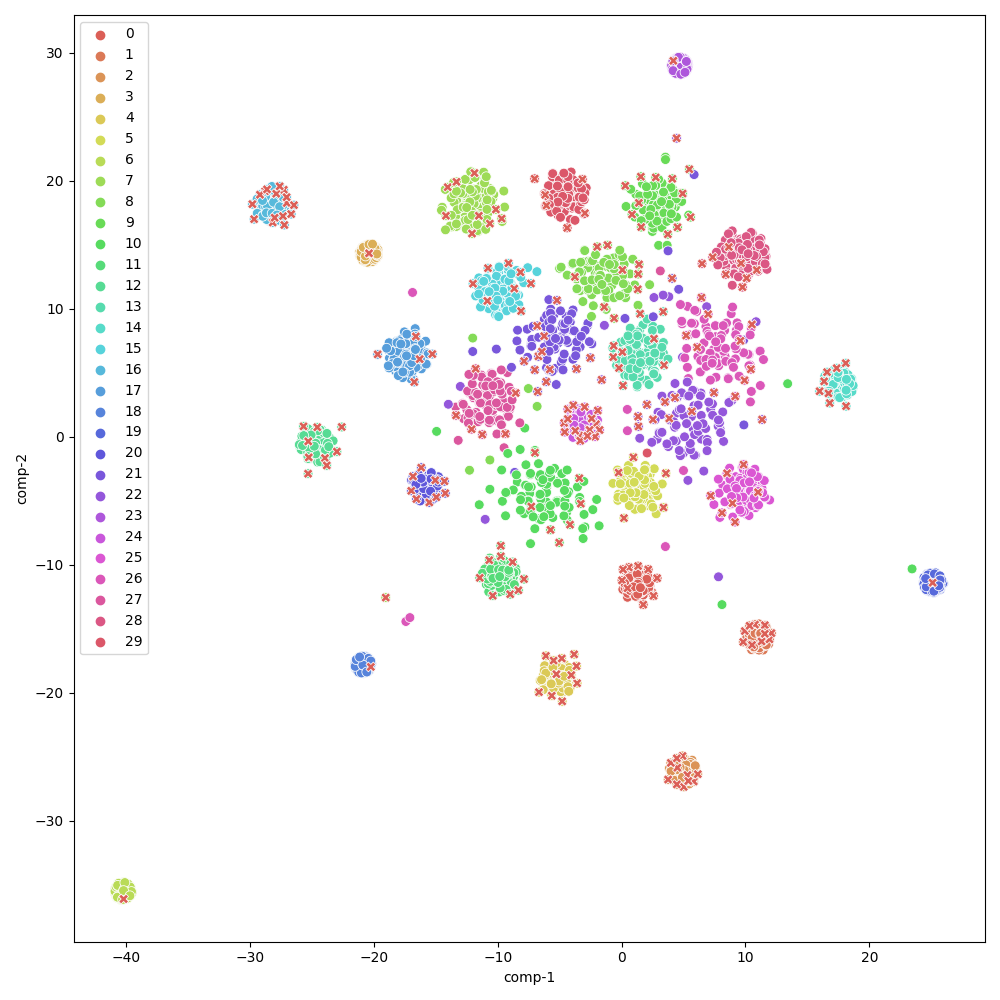

In [170]:
df = pd.DataFrame()

df["comp-1"] = X_tsne[:,0]
df["comp-2"] = X_tsne[:,1]
plt.figure(figsize=(10,10))

train_df = df.iloc[:X.shape[0]]
train_df["y"] = y[:,0]
ax = sns.scatterplot(x="comp-1", y="comp-2", hue=train_df.y.tolist(), s=50,
                    palette=sns.color_palette("hls", n_classes), legend=True,
                    data=train_df)

protos_df = df.iloc[X.shape[0]:]
protos_df["y"] = 0
ax = sns.scatterplot(x="comp-1", y="comp-2", hue=protos_df.y.tolist(), marker="X", s=50,
                    palette=sns.color_palette("hls", 1), legend=False,
                    data=protos_df)

plt.tight_layout()